<div align="center">
<img src="https://raw.githubusercontent.com/WSU-AI-in-ME/ai-in-me-1/main/img/wsu_logo_horizontal.png" alt="Wayne State University Logo" width="320">
<h1>Practice 9: From Manufacturing Sound to Neural Network Inputs</h1>
</div>

ME 5995: AI in Mechanical Engineering I, Wayne State University  
Optional, ungraded self-study. Self-check solution.  
Estimated core route: 60 minutes. Optional exploration: 30 minutes.

[Course Repository](https://github.com/WSU-AI-in-ME/ai-in-me-1)  
[Practice Index](https://github.com/WSU-AI-in-ME/ai-in-me-1/blob/main/Practice_index.ipynb)

[Open in Colab](https://colab.research.google.com/github/WSU-AI-in-ME/ai-in-me-1/blob/main/practice/week09/practice09_sound_to_logmel_solution.ipynb)

## Student Information

Double-click this Markdown cell to edit.

**Student name:** Instructor Example  
**WSU AccessID:** example00

## Overview and learning objectives

A microphone records amplitude over time. Lab 8 receives a compact time-frequency
representation instead. This Practice makes the steps between those two inputs
visible. We do not train a model or search for a better feature representation.

By the end, you can explain recording and segment arrays, trace one input to its
parent, distinguish one-second segments from short analysis frames, reproduce
the course log-mel shape, and fit global scaling using training inputs only.

Follow each completed example, attempt the marked TRY IT, then inspect its output
and write a short explanation. Code-task cells initially contain comments so all
provided examples run before you attempt them. An empty task cell is not an answer.

## Dataset context and provenance

MIMII public 1.0 contains industrial machine sounds recorded with an eight-channel
microphone array. The course derivative uses Channel 1 from the 0 dB factory-noise
mixture, 16 kHz, PCM16, and normal recordings only. Machine IDs are local within
each machine type. The four labels are fan, pump, slider and valve.

The original benchmark concerns anomalous sound detection. Our supervised
machine-type classification is a course-derived task, not fault diagnosis.
The existing public classification pool has 160 normal recordings: four types,
four IDs per type, ten recordings per type/ID. Every recording is ten seconds.
We reuse its metadata and WAVs, without adding a new audio or feature dataset.
The anomaly-task membership is not selected for this Practice.

One existing fan recording illustrates every signal-processing step. Supplied
infrastructure later applies the same recipe to all 160 recordings. Students
do not write bulk extraction. IDs support lineage, not predictors.
Lab 8/9 and HW5 separately use precomputed log-mel from 800 recordings. Their
counts and fitted scaling statistics need not match this smaller Practice.

## Required files and provided setup

Use NumPy, pandas, Matplotlib, SciPy and IPython. For local work, install the
required packages in your local Python environment. If a requirements.txt file
is provided, you may use it as an installation aid.

The existing public `data/mimii/metadata.csv` and its selected WAV paths are the
only data inputs. The provided setup pins the published course version and caches
downloads. It can also reuse an existing local `mimii` directory. No private
800-recording NPZ, duplicate example WAV or mel-weight file is required.

Run the marked infrastructure cells unchanged. They contain the minimal loops
needed to download files, construct the fixed parent split and repeat extraction.
You do not need to write those loops or unfamiliar array-framing operations.
Required student edits remain short explicit statements. There are no checksum
checks or private-version checks in this notebook.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import get_window
from IPython.display import display

In [2]:
# PROVIDED: existing public data, pinned so the same files are used later.
data_url = "https://raw.githubusercontent.com/WSU-AI-in-ME/ai-in-me-1/a6db3d74a4e7eedf4956b8128c7a68987e9927a2/data/mimii/"
data_folder = Path("mimii")
data_folder.mkdir(parents=True, exist_ok=True)
metadata_file = data_folder / "metadata.csv"
if not metadata_file.is_file():
    urlretrieve(data_url + "metadata.csv", metadata_file)

## 1. Understand the files before processing

A CSV is a table: one row describes one whole recording. Opening it does not
fit a transformation. Start with its columns and shape, then select the existing
normal classification membership. Do not print thousands of raw sample values.

In [3]:
metadata = pd.read_csv(metadata_file)
print("Metadata columns:", metadata.columns.to_list())
print("All public metadata rows/columns:", metadata.shape)
classification_mask = metadata["classification_included"] == True
recordings = metadata.loc[classification_mask].copy()
recordings = recordings.sort_values("recording_id")
recordings = recordings.reset_index(drop=True)
print("Classification metadata rows/columns:", recordings.shape)
display(recordings[["recording_id", "machine_type", "machine_id", "condition"]].head())

Metadata columns: ['recording_id', 'file_path', 'source_file', 'machine_type', 'machine_id', 'condition', 'classification_included', 'anomaly_included', 'snr_db', 'channel', 'sample_rate', 'duration_seconds', 'num_samples', 'sha256']
All public metadata rows/columns: (220, 14)
Classification metadata rows/columns: (160, 14)


,recording_id,machine_type,machine_id,condition
0,fan_id_00_normal_00000025_80da26572c,fan,id_00,normal
1,fan_id_00_normal_00000026_7683cb94c3,fan,id_00,normal
2,fan_id_00_normal_00000114_d54f14163d,fan,id_00,normal
3,fan_id_00_normal_00000116_40dc056a77,fan,id_00,normal
4,fan_id_00_normal_00000281_6806346013,fan,id_00,normal


In [4]:
# Labels are targets, not audio inputs. IDs are local within machine type.
recordings["label"] = -1
recordings.loc[recordings["machine_type"] == "fan", "label"] = 0
recordings.loc[recordings["machine_type"] == "pump", "label"] = 1
recordings.loc[recordings["machine_type"] == "slider", "label"] = 2
recordings.loc[recordings["machine_type"] == "valve", "label"] = 3
class_names = np.array(["fan", "pump", "slider", "valve"])
recording_ids = recordings["recording_id"].to_numpy()
display(pd.crosstab(recordings["machine_type"], recordings["machine_id"]))

machine_id,id_00,id_02,id_04,id_06
machine_type,,,,
fan,10,10,10,10
pump,10,10,10,10
slider,10,10,10,10
valve,10,10,10,10


## 2. Read one documented waveform

The example is the first row after sorting the existing classification records:
a fan recording. Its original source path remains in the public metadata.
The existing course mono PCM16 file is read without additional normalization.

`sample_rate` counts samples per second. A PCM16 sample is a signed integer;
dividing by 32768 expresses digital amplitude relative to full scale. This is
not a microphone-pressure calibration and the plotted amplitude is not pascals.

In [5]:
# PROVIDED: fetch the one existing demonstration WAV only if it is not cached.
example_path = recordings.loc[0, "file_path"]
waveform_file = data_folder / example_path
if not waveform_file.is_file():
    waveform_file.parent.mkdir(parents=True, exist_ok=True)
    urlretrieve(data_url + example_path, waveform_file)
display(recordings.loc[[0], ["recording_id", "machine_type", "machine_id", "condition", "source_file"]])
sample_rate, pcm = wavfile.read(waveform_file)
audio = pcm.astype(np.float64) / 32768.0
duration_seconds = len(audio) / sample_rate
time_seconds = np.arange(len(audio)) / sample_rate
print("Sample rate (Hz):", sample_rate)
print("PCM shape and dtype:", pcm.shape, pcm.dtype)
print("Duration (s):", duration_seconds)

,recording_id,machine_type,machine_id,condition,source_file
0,fan_id_00_normal_00000025_80da26572c,fan,id_00,normal,0_dB_fan/fan/id_00/normal/00000025.wav


Sample rate (Hz): 16000
PCM shape and dtype: (160000,) int16
Duration (s): 10.0


### TRY IT 1: Read the loaded waveform

Print `audio.shape`, `pcm.dtype` and `sample_rate`. Print the example's machine
type, machine ID and condition from row 0 of `recordings`. Identify which output
describes sample count and which describes samples per second.

In [6]:
print("Waveform shape:", audio.shape)
print("Stored sample type:", pcm.dtype)
print("Samples per second:", sample_rate)
print("Machine type:", recordings.loc[0, "machine_type"])
print("Machine ID:", recordings.loc[0, "machine_id"])
print("Condition:", recordings.loc[0, "condition"])

Waveform shape: (160000,)
Stored sample type: int16
Samples per second: 16000
Machine type: fan
Machine ID: id_00
Condition: normal


What does one metadata row describe, and what does one waveform array element describe?

**Self-check:** A metadata row describes one whole recording. One element of its waveform is one sampled digital amplitude, not an independent recording.

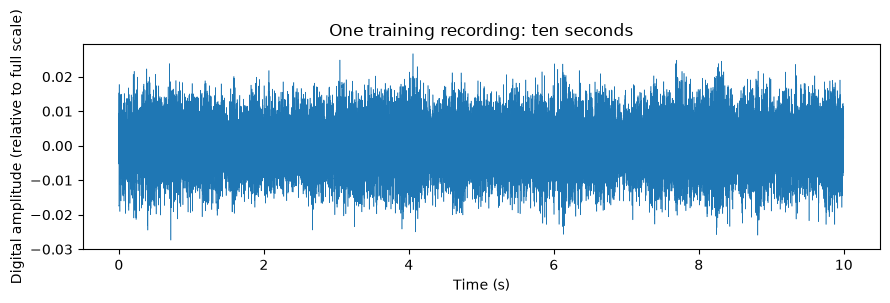

In [7]:
plt.figure(figsize=(9, 3))
plt.plot(time_seconds, audio, linewidth=0.4)
plt.xlabel("Time (s)")
plt.ylabel("Digital amplitude (relative to full scale)")
plt.title("One training recording: ten seconds")
plt.tight_layout()
plt.show()

## 3. Assign partitions to recordings first

The public metadata has no predefined split. This Practice assigns 6/2/2
recordings per type/ID with seed 42: 96 training, 32 validation and 32 test parents.
The provided grouping cell below creates this one fixed teaching manifest.
All four local IDs are represented in all partitions. This evaluates held-out
recordings of represented IDs, not generalization to unseen machines or sessions.

Assign a parent to a partition before distributing its segments. Deterministic
log-mel extraction may be cached earlier, but caching does not justify splitting
related windows randomly or fitting scaling on all partitions.

In [8]:
# PROVIDED: assign complete parents within each type/ID group. Run unchanged.
recordings["partition"] = ""
split_generator = np.random.default_rng(42)
parent_groups = recordings.groupby(["machine_type", "machine_id"], sort=True)
for group_name, group_rows in parent_groups:
    shuffled_parent_rows = split_generator.permutation(group_rows.index.to_numpy())
    recordings.loc[shuffled_parent_rows[:6], "partition"] = "train"
    recordings.loc[shuffled_parent_rows[6:8], "partition"] = "validation"
    recordings.loc[shuffled_parent_rows[8:], "partition"] = "test"

In [9]:
recording_partitions = recordings["partition"].to_numpy()
recording_types = recordings["machine_type"]
partition_counts = pd.crosstab(recording_types, recordings["partition"])
display(partition_counts)
train_parent_mask = recording_partitions == "train"
validation_parent_mask = recording_partitions == "validation"
test_parent_mask = recording_partitions == "test"
print("Training parents:", train_parent_mask.sum())
print("Validation parents:", validation_parent_mask.sum())
print("Test parents:", test_parent_mask.sum())

partition,test,train,validation
machine_type,,,
fan,8,24,8
pump,8,24,8
slider,8,24,8
valve,8,24,8


Training parents: 96
Validation parents: 32
Test parents: 32


Why must all segments from one recording inherit the same partition?

**Self-check:** Sibling windows can carry nearly the same recording-specific sound into training and evaluation. Keep every parent entirely in one partition.

## 4. Divide a recording into one-second segments

At 16000 Hz, one second contains 16000 samples. NumPy slices exclude the upper
bound: `audio[0:16000]` covers the first second and `audio[16000:32000]` covers the
second. There is no overlap between these segments. Ten segments inherit the
same training membership and machine-type label as the parent.

First segment: (16000,)
Second segment: (16000,)


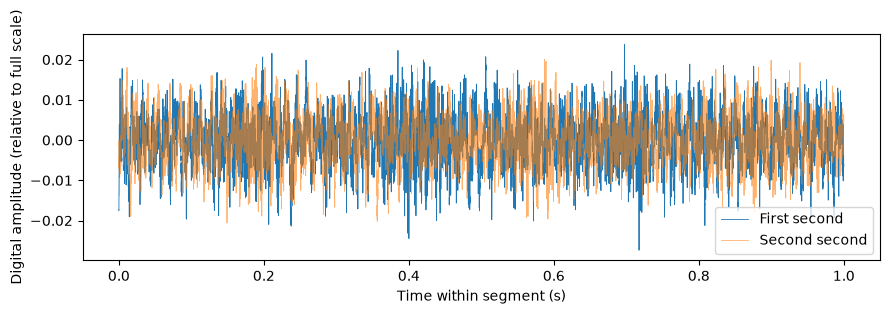

In [10]:
samples_per_segment = sample_rate
segment_1 = audio[0:16000]
segment_2 = audio[16000:32000]
print("First segment:", segment_1.shape)
print("Second segment:", segment_2.shape)
segment_time = np.arange(samples_per_segment) / sample_rate
plt.figure(figsize=(9, 3))
plt.plot(segment_time, segment_1, label="First second", linewidth=0.6)
plt.plot(segment_time, segment_2, label="Second second", linewidth=0.6, alpha=0.6)
plt.xlabel("Time within segment (s)")
plt.ylabel("Digital amplitude (relative to full scale)")
plt.legend()
plt.tight_layout()
plt.show()

### TRY IT 2: Extract the third second

Create `segment_3` using an explicit slice and print its shape. State which
partition it belongs to. Do not construct a new random split.

In [11]:
segment_3 = audio[32000:48000]
print("Third segment:", segment_3.shape)
print("Inherited partition:", recordings.loc[0, "partition"])

Third segment: (16000,)
Inherited partition: train


## 5. Inspect short frames and the Hann window

A one-second **segment** is one model input. Inside it, an analysis **frame** is
512 samples (0.032 s), advanced by a 256-sample hop (0.016 s). These analysis
frames overlap by 50%, even though the one-second input segments do not overlap.

The periodic Hann window tapers frame edges before the FFT. It reduces abrupt
edge effects but changes spectral peak width and amplitude. It is not another
dataset split or a recording-wise amplitude normalization.

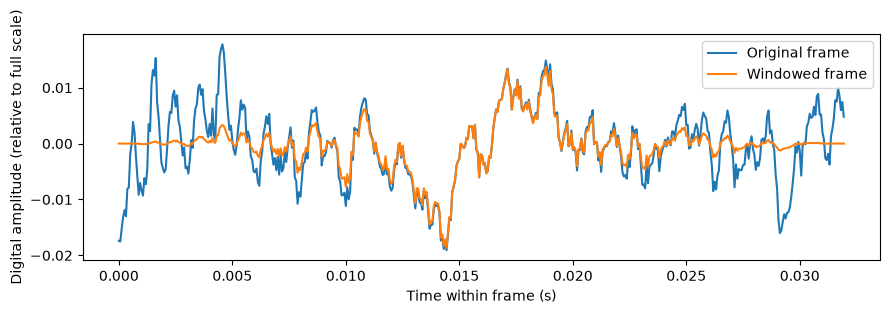

In [12]:
frame_length = 512
hop_length = 256
frame = segment_1[0:512]
hann_window = get_window("hann", frame_length, fftbins=True)
windowed_frame = frame * hann_window
frame_time = np.arange(frame_length) / sample_rate
plt.figure(figsize=(9, 3))
plt.plot(frame_time, frame, label="Original frame")
plt.plot(frame_time, windowed_frame, label="Windowed frame")
plt.xlabel("Time within frame (s)")
plt.ylabel("Digital amplitude (relative to full scale)")
plt.legend()
plt.tight_layout()
plt.show()

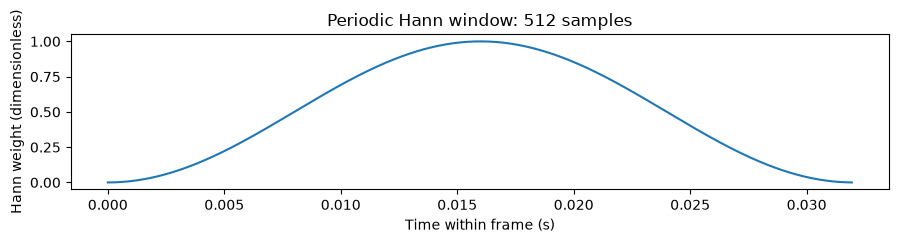

In [13]:
plt.figure(figsize=(9, 2.5))
plt.plot(frame_time, hann_window)
plt.xlabel("Time within frame (s)")
plt.ylabel("Hann weight (dimensionless)")
plt.title("Periodic Hann window: 512 samples")
plt.tight_layout()
plt.show()

### From one frame to frequency bins

For real-valued data, `rfft` returns the nonnegative-frequency bins including
zero and Nyquist. A 512-sample FFT has 257 such bins. Bin spacing is
16000/512 = 31.25 Hz; actual ability to resolve nearby tones also depends on the
window and observation length. This example uses squared FFT magnitude, not a
calibrated power spectral density in Pa-squared per Hz.

FFT shape: (257,)
Bin spacing (Hz): 31.25


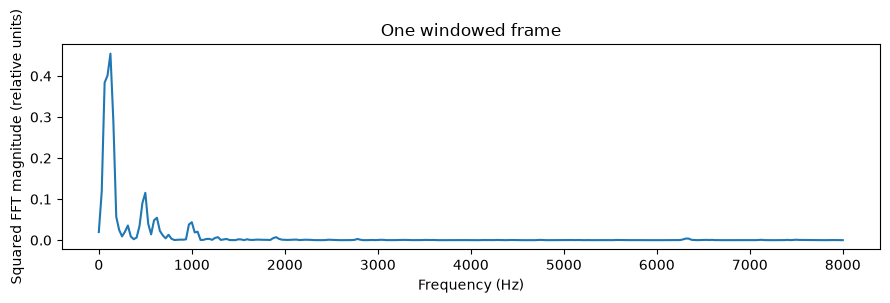

In [14]:
frame_fft = np.fft.rfft(windowed_frame)
frame_power = np.abs(frame_fft) ** 2
frequencies_hz = np.fft.rfftfreq(frame_length, d=1.0 / sample_rate)
print("FFT shape:", frame_fft.shape)
print("Bin spacing (Hz):", sample_rate / frame_length)
plt.figure(figsize=(9, 3))
plt.plot(frequencies_hz, frame_power)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Squared FFT magnitude (relative units)")
plt.title("One windowed frame")
plt.tight_layout()
plt.show()

### Provided framing infrastructure: run unchanged

`sliding_window_view` exposes consecutive 512-sample slices; selecting every
256th start produces the desired hop. Read the output shapes, but do not rewrite
this infrastructure. Frames are rows; multiplying by the Hann vector applies the
same weights to each row. The FFT operates along each frame (`axis=1`). We
transpose its squared magnitude so frequency becomes rows and time becomes columns.

No padding is added. The number of complete frames is
`1 + (16000 - 512) // 256 = 61`. A longer frame trades finer frequency-bin spacing
for less precise time localization; we keep all extraction settings fixed here.

In [15]:
# PROVIDED: exact framing and FFT recipe used for the cached features.
all_frame_views = np.lib.stride_tricks.sliding_window_view(segment_1, frame_length)
frames = all_frame_views[::hop_length]
windowed_frames = frames * hann_window
complex_spectra = np.fft.rfft(windowed_frames, axis=1)
power_spectrogram = np.abs(complex_spectra.T) ** 2
frame_centers_seconds = (np.arange(frames.shape[0]) * hop_length + frame_length / 2) / sample_rate
print("Frames (time, samples):", frames.shape)
print("Power (frequency, time):", power_spectrogram.shape)

Frames (time, samples): (61, 512)
Power (frequency, time): (257, 61)


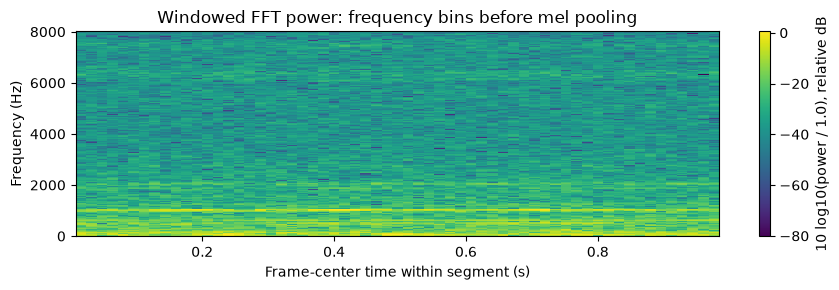

In [16]:
# A log display makes weak frequency content visible; the stored values here remain linear power.
power_display = 10 * np.log10(np.maximum(power_spectrogram, 1e-12))
plt.figure(figsize=(9, 3))
plt.pcolormesh(frame_centers_seconds, frequencies_hz, power_display, shading="nearest")
plt.xlabel("Frame-center time within segment (s)")
plt.ylabel("Frequency (Hz)")
plt.colorbar(label="10 log10(power / 1.0), relative dB")
plt.title("Windowed FFT power: frequency bins before mel pooling")
plt.tight_layout()
plt.show()

Report the number of frames and explain why a segment is not a frame.

**Self-check:** There are 61 frames. One model input spans one second; each internal analysis frame spans 0.032 seconds and neighboring frames overlap.

## 6. Pool FFT power into mel bands, then take the logarithm

The supplied filterbank has shape `(32, 257)`. Each row weights a range of
frequency bins. Mel spacing is approximately linear at low frequencies and
logarithmic at higher frequencies. The course uses the Slaney convention with
area normalization; other conventions and defaults can produce different values.

Inspect two filters first. You do not need to derive their locations. The matrix
product `mel_weights @ power_spectrogram` sums weighted power into 32 bands.
Its shape follows `(32,257) @ (257,61) = (32,61)`.

### Provided filterbank construction: run unchanged

This block constructs the exact Slaney triangular weights without a new data
file or another package dependency. Frequency-edge arithmetic and extra array
axes are supplied infrastructure. Your task is to understand the resulting
32-by-257 matrix and its product with power, not reconstruct these formulas.

In [17]:
# PROVIDED: exact Slaney mel scale and area-normalized weights.
upper_mel = 15 + np.log(8000 / 1000) / (np.log(6.4) / 27)
mel_edges = np.linspace(0, upper_mel, 34)
hz_edges = mel_edges * (200.0 / 3)
log_region = mel_edges >= 15
hz_edges[log_region] = 1000 * np.exp((np.log(6.4) / 27) * (mel_edges[log_region] - 15))
lower_edges = hz_edges[:-2, None]
center_edges = hz_edges[1:-1, None]
upper_edges = hz_edges[2:, None]
rising_weights = (frequencies_hz[None, :] - lower_edges) / (center_edges - lower_edges)
falling_weights = (upper_edges - frequencies_hz[None, :]) / (upper_edges - center_edges)
triangles = np.maximum(0, np.minimum(rising_weights, falling_weights))
mel_weights = triangles * 2 / (upper_edges - lower_edges)

Mel weights: (32, 257)


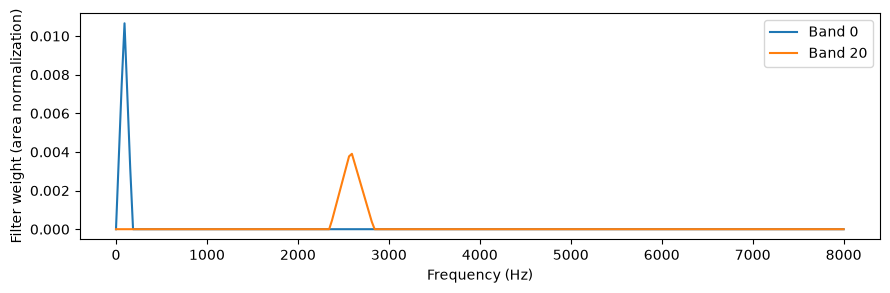

In [18]:
print("Mel weights:", mel_weights.shape)
plt.figure(figsize=(9, 3))
plt.plot(frequencies_hz, mel_weights[0], label="Band 0")
plt.plot(frequencies_hz, mel_weights[20], label="Band 20")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Filter weight (area normalization)")
plt.legend()
plt.tight_layout()
plt.show()

In [19]:
mel_power = mel_weights @ power_spectrogram
reference_power = 1.0
print("Mel power shape:", mel_power.shape)
# Completed scalar example: a tenfold power ratio gives 10 dB.
example_power = 10.0
example_floored_power = np.maximum(example_power, 1e-12)
example_log_power = 10 * np.log10(example_floored_power / reference_power)
print("Example log-power (relative dB):", example_log_power)

Mel power shape: (32, 61)
Example log-power (relative dB): 10.0


The floor prevents `log10(0)`. Power uses a factor of **10**, not the
amplitude factor of 20. A tenfold power ratio changes this representation by
10 dB. The fixed numerical reference is 1.0; there is no per-segment maximum
reference or top-dB clipping. These values are **not dB SPL**. The logarithm
compresses the range but does not standardize the dataset.

### TRY IT 3: Apply the logarithm to the matrix

Use `np.maximum(mel_power, 1e-12)` to create `floored_power_try`. Then create
`logmel_try` with `10 * np.log10(floored_power_try / reference_power)` and print
its shape. The scalar example above shows the same transformation. The supplied
cell below repeats it so an unfinished task does not block the figures.

In [20]:
floored_power_try = np.maximum(mel_power, 1e-12)
logmel_try = 10 * np.log10(floored_power_try / reference_power)
print("Log-mel shape:", logmel_try.shape)

Log-mel shape: (32, 61)


In [21]:
# PROVIDED: continue the completed walkthrough after your attempt.
floored_mel_power = np.maximum(mel_power, 1e-12)
logmel = 10 * np.log10(floored_mel_power / reference_power)
print("Log-mel shape:", logmel.shape)
print("Power floor expressed in relative dB:", 10 * np.log10(1e-12))

Log-mel shape: (32, 61)
Power floor expressed in relative dB: -120.0


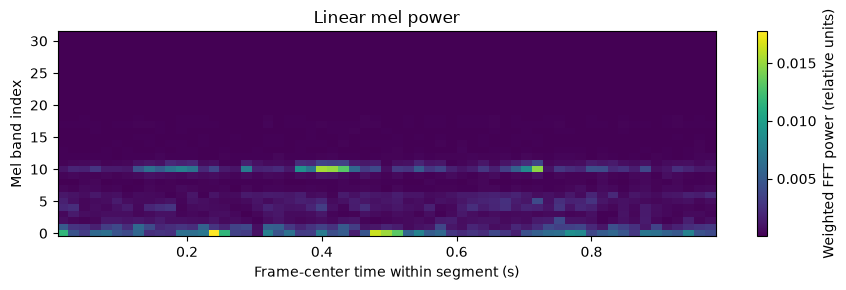

In [22]:
mel_band_numbers = np.arange(32)
plt.figure(figsize=(9, 3))
plt.pcolormesh(frame_centers_seconds, mel_band_numbers, mel_power, shading="nearest")
plt.xlabel("Frame-center time within segment (s)")
plt.ylabel("Mel band index")
plt.colorbar(label="Weighted FFT power (relative units)")
plt.title("Linear mel power")
plt.tight_layout()
plt.show()

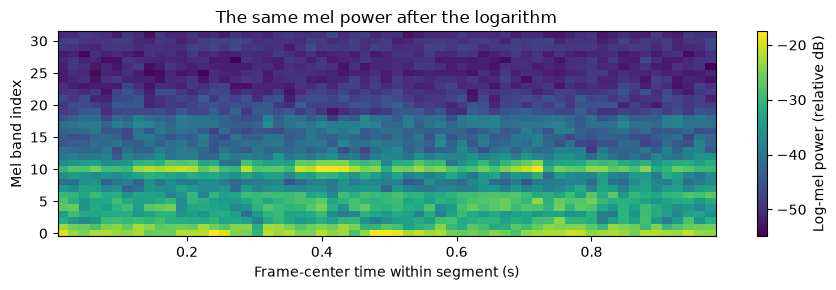

In [23]:
plt.figure(figsize=(9, 3))
plt.pcolormesh(frame_centers_seconds, mel_band_numbers, logmel, shading="nearest")
plt.xlabel("Frame-center time within segment (s)")
plt.ylabel("Mel band index")
plt.colorbar(label="Log-mel power (relative dB)")
plt.title("The same mel power after the logarithm")
plt.tight_layout()
plt.show()

## 7. Repeat the recipe and follow each input to its parent

The next supplied block repeats the demonstrated recipe for all 160 existing
normal classification recordings. It downloads only missing WAVs and processes
one recording at a time. The first run may take longer because it transfers
about 51 MB of existing audio. Run it unchanged; writing the download/extraction
loop is not student work. Do not repeatedly rerun downloads to change the split.

`X` has 1600 segment rows and 32x61 float32 values per row. Every ten rows share
one parent and partition. The first recording's first second becomes `X[0]`.
Small float32 rounding differences from the float64 walkthrough are expected.
This is a correspondence check, not a training result or a new published NPZ.

In [24]:
# PROVIDED: bounded download/extraction infrastructure. Run unchanged.
X = np.empty((len(recordings) * 10, 32, 61), dtype=np.float32)
for parent_row in range(len(recordings)):
    relative_wav = recordings.loc[parent_row, "file_path"]
    local_wav = data_folder / relative_wav
    if not local_wav.is_file():
        local_wav.parent.mkdir(parents=True, exist_ok=True)
        urlretrieve(data_url + relative_wav, local_wav)
    current_rate, current_pcm = wavfile.read(local_wav)
    current_audio = current_pcm.astype(np.float64) / 32768.0
    current_segments = current_audio.reshape(10, 16000)
    current_views = np.lib.stride_tricks.sliding_window_view(current_segments, 512, axis=1)
    current_frames = current_views[:, ::256, :]
    current_windowed = current_frames * hann_window
    current_fft = np.fft.rfft(current_windowed, axis=2)
    current_power = np.abs(current_fft.transpose(0, 2, 1)) ** 2
    current_mel = mel_weights @ current_power
    current_logmel = 10 * np.log10(np.maximum(current_mel, 1e-12))
    first_row = parent_row * 10
    X[first_row:first_row + 10] = current_logmel.astype(np.float32)
recording_index = np.repeat(np.arange(len(recordings)), 10)
y = np.repeat(recordings["label"].to_numpy(), 10)
print("All segment inputs:", X.shape, X.dtype)
print("Targets and parent indices:", y.shape, recording_index.shape)

All segment inputs: (1600, 32, 61) float32
Targets and parent indices: (1600,) (1600,)


In [25]:
# Follow the first twelve segment rows to their parent recording.
segment_rows = np.arange(12)
parent_rows = recording_index[:12]
parent_ids = recording_ids[parent_rows]
preview = pd.DataFrame()
preview["Segment row"] = segment_rows
preview["Parent row"] = parent_rows
preview["Recording ID"] = parent_ids
preview["Partition"] = recording_partitions[parent_rows]
display(preview)

,Segment row,Parent row,Recording ID,Partition
0,0,0,fan_id_00_normal_00000025_80da26572c,train
1,1,0,fan_id_00_normal_00000025_80da26572c,train
2,2,0,fan_id_00_normal_00000025_80da26572c,train
3,3,0,fan_id_00_normal_00000025_80da26572c,train
4,4,0,fan_id_00_normal_00000025_80da26572c,train
5,5,0,fan_id_00_normal_00000025_80da26572c,train
6,6,0,fan_id_00_normal_00000025_80da26572c,train
7,7,0,fan_id_00_normal_00000025_80da26572c,train
8,8,0,fan_id_00_normal_00000025_80da26572c,train
9,9,0,fan_id_00_normal_00000025_80da26572c,train


In [26]:
cached_segment = X[0]
difference = logmel - cached_segment
maximum_difference = np.max(np.abs(difference))
flat_segment = cached_segment.reshape(1952)
print("Example parent row:", recording_index[0])
print("Maximum absolute difference (relative dB):", maximum_difference)
print("Flat input shape:", flat_segment.shape)

Example parent row: 0
Maximum absolute difference (relative dB): 1.9065562355535803e-06
Flat input shape: (1952,)


## 8. Fit one global transformation using training inputs only

Copy each parent's partition to all of its segments. Boolean masks then select
the matching rows. This is indexing an existing manifest, not generating a new
random segment split.

In [27]:
segment_partitions = recording_partitions[recording_index]
train_mask = segment_partitions == "train"
validation_mask = segment_partitions == "validation"
test_mask = segment_partitions == "test"
X_train = X[train_mask]
X_validation = X[validation_mask]
X_test = X[test_mask]
print("Training inputs:", X_train.shape)
print("Validation inputs:", X_validation.shape)
print("Test inputs:", X_test.shape)

Training inputs: (960, 32, 61)
Validation inputs: (320, 32, 61)
Test inputs: (320, 32, 61)


Compute **one scalar mean** and **one population standard deviation** over
all elements in `X_train`, without specifying an axis. Then transform each value
with `(value - training_mean) / training_std`. NumPy `std()` uses population
normalization (`ddof=0`) by default. We keep float32 arithmetic as in the Labs.

This is not a different statistic for every coordinate, band or segment. The
same affine transform preserves relative level differences across segments.
It changes numerical scale while retaining the input shape.

In [28]:
# Completed small-array analogy: one pair fitted on training values only.
example_train = np.array([1.0, 2.0, 3.0])
example_validation = np.array([2.0, 4.0])
example_mean = example_train.mean()
example_std = example_train.std()
example_validation_scaled = (example_validation - example_mean) / example_std
print("Example training mean/SD:", example_mean, example_std)
print("Example transformed validation:", example_validation_scaled)

Example training mean/SD: 2.0 0.816496580927726
Example transformed validation: [0.         2.44948974]


### TRY IT 4: Fit training statistics and reuse them

Create `training_mean_try = X_train.mean()` and `training_std_try = X_train.std()`.
Use those scalars to create `train_scaled_try` and `validation_scaled_try`.
Print the statistic shapes, the scaled input shapes and each partition's overall
mean/SD. Do not fit a new pair on validation. Later cells repeat the correct
transformation so incomplete task code does not block the supplied examples.

In [29]:
training_mean_try = X_train.mean()
training_std_try = X_train.std()
train_scaled_try = (X_train - training_mean_try) / training_std_try
validation_scaled_try = (X_validation - training_mean_try) / training_std_try
print("Statistic shapes:", training_mean_try.shape, training_std_try.shape)
print("Input shapes:", train_scaled_try.shape, validation_scaled_try.shape)
print("Training mean/SD:", train_scaled_try.mean(), train_scaled_try.std())
print("Validation mean/SD:", validation_scaled_try.mean(), validation_scaled_try.std())

Statistic shapes: () ()
Input shapes: (960, 32, 61) (320, 32, 61)
Training mean/SD: -5.4614793e-07 1.0
Validation mean/SD: 0.033233915 0.97952986


In [30]:
# PROVIDED: complete transformation for the remaining visual examples.
training_mean = X_train.mean()
training_std = X_train.std()
X_train_scaled = (X_train - training_mean) / training_std
print("Training mean (relative dB):", training_mean)
print("Training population SD (relative dB):", training_std)
print("Statistic shape:", training_mean.shape, training_std.shape)
print("Scaled training shape:", X_train_scaled.shape)

Training mean (relative dB): -40.36992
Training population SD (relative dB): 8.805128
Statistic shape: () ()
Scaled training shape: (960, 32, 61)


In [31]:
# PROVIDED: same scalar pair for every partition, including test.
X_validation_scaled = (X_validation - training_mean) / training_std
X_test_scaled = (X_test - training_mean) / training_std
print("Scaled training mean and SD:", X_train_scaled.mean(), X_train_scaled.std())
print("Scaled validation mean and SD:", X_validation_scaled.mean(), X_validation_scaled.std())

Scaled training mean and SD: -5.4614793e-07 1.0
Scaled validation mean and SD: 0.033233915 0.97952986


Why is fitting on all of X inappropriate, and must scaled validation have mean 0 and SD 1?

**Self-check:** All of X includes validation/test information, which must not fit preprocessing. Validation reuses the training pair and need not have mean 0 and SD 1.

## 9. Inspect the resulting distributions

Plotting an empirical histogram does not establish a Gaussian distribution.
Global standardization makes the whole training tensor approximately mean 0 and
SD 1, within floating-point precision. Validation and test distributions, and
individual segments, need not have those statistics.

The following plots use a fixed reproducible subsample of flattened values to
keep rendering small. Each subset uses its own density normalization and shared
bin edges. The printed statistics above use **all** values, not this plot sample.
Values outside the displayed histogram range are not counted in its density.

In [32]:
train_values = X_train.reshape(-1)
validation_values = X_validation.reshape(-1)
train_scaled_values = X_train_scaled.reshape(-1)
validation_scaled_values = X_validation_scaled.reshape(-1)
raw_bins = np.linspace(-120, 40, 81)
scaled_bins = np.linspace(-10, 10, 81)

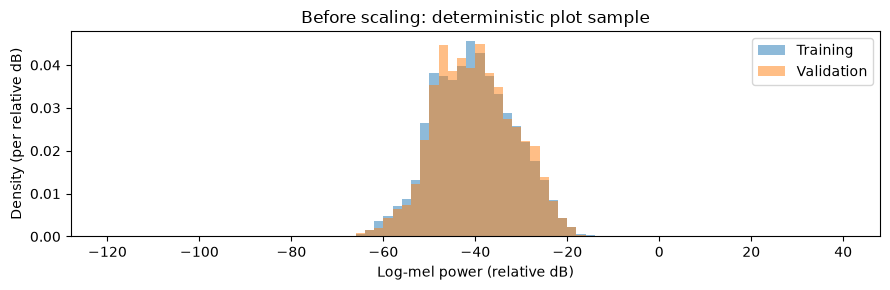

In [33]:
plt.figure(figsize=(9, 3))
plt.hist(train_values[::100], bins=raw_bins, density=True, alpha=0.5, label="Training")
plt.hist(validation_values[::100], bins=raw_bins, density=True, alpha=0.5, label="Validation")
plt.xlabel("Log-mel power (relative dB)")
plt.ylabel("Density (per relative dB)")
plt.title("Before scaling: deterministic plot sample")
plt.legend()
plt.tight_layout()
plt.show()

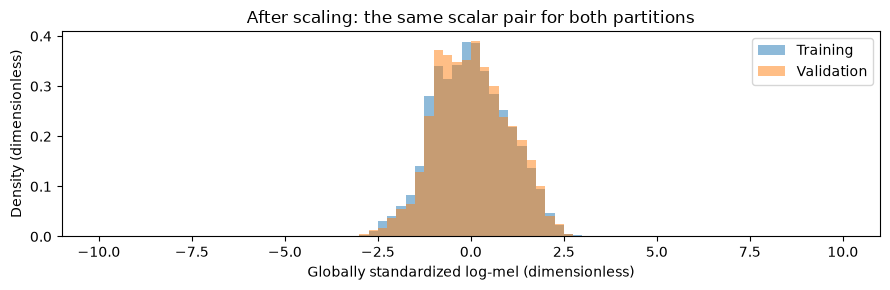

In [34]:
plt.figure(figsize=(9, 3))
plt.hist(train_scaled_values[::100], bins=scaled_bins, density=True, alpha=0.5, label="Training")
plt.hist(validation_scaled_values[::100], bins=scaled_bins, density=True, alpha=0.5, label="Validation")
plt.xlabel("Globally standardized log-mel (dimensionless)")
plt.ylabel("Density (dimensionless)")
plt.title("After scaling: the same scalar pair for both partitions")
plt.legend()
plt.tight_layout()
plt.show()

In [35]:
# Three segment summaries use all 1952 coordinates in each segment.
segment_stats = pd.DataFrame()
segment_stats["Training segment row"] = [0, 1, 2]
segment_stats["Mean after global scaling"] = [X_train_scaled[0].mean(), X_train_scaled[1].mean(), X_train_scaled[2].mean()]
segment_stats["SD after global scaling"] = [X_train_scaled[0].std(), X_train_scaled[1].std(), X_train_scaled[2].std()]
display(segment_stats)

,Training segment row,Mean after global scaling,SD after global scaling
0,0,-0.075658,1.002451
1,1,-0.117664,0.966312
2,2,-0.125990,0.950706


## Core route complete

You have connected an existing public waveform to the same 32x61 representation
used in Lab 8, preserved recording membership and applied training-global scaling.
Practice uses 160 recordings; Lab/HW use the separate 800-recording feature package.
Their independently fitted scaling statistics need not match.
No model was fitted and no test score guided a decision. Continue to the optional
section only if you want to inspect the information removed by segment-wise scaling.

## Optional challenge: Global versus segment-wise normalization

Compare the first and second training segments below. Global scaling uses the
same pair for both. Segment-wise z-scores fit a separate pair for each and remove
their mean-level and overall-spread differences. Neither choice is a universal
winner; the course keeps global scaling fixed. We do not run a model comparison.

In [36]:
first_raw = X_train[0]
second_raw = X_train[1]
first_global = X_train_scaled[0]
second_global = X_train_scaled[1]
first_local = (first_raw - first_raw.mean()) / first_raw.std()
second_local = (second_raw - second_raw.mean()) / second_raw.std()
print("First global mean/SD:", first_global.mean(), first_global.std())
print("Second global mean/SD:", second_global.mean(), second_global.std())
print("First local mean/SD:", first_local.mean(), first_local.std())
print("Second local mean/SD:", second_local.mean(), second_local.std())

First global mean/SD: -0.07565817 1.0024514
Second global mean/SD: -0.117663585 0.96631235
First local mean/SD: 4.0648413e-07 0.99999994
Second local mean/SD: -2.1887607e-07 1.0


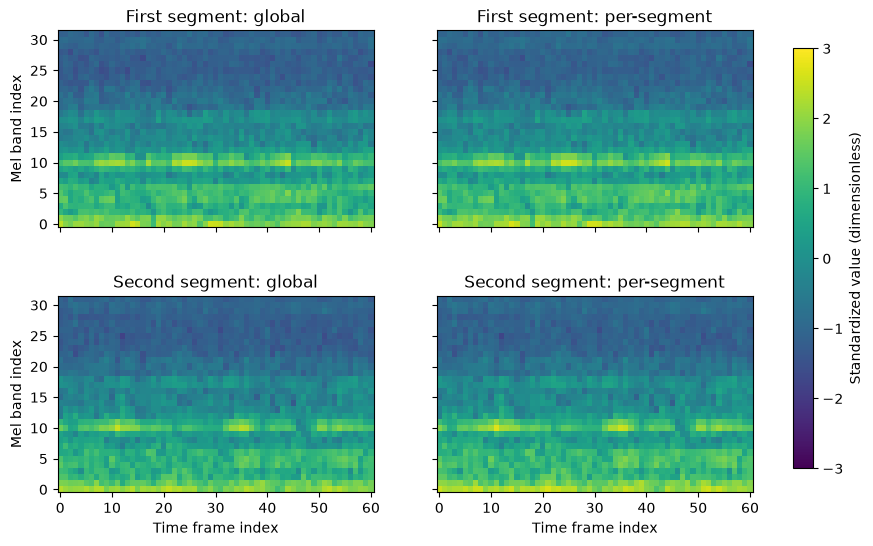

In [37]:
figure, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey=True)
image = axes[0, 0].imshow(first_global, origin="lower", aspect="auto", vmin=-3, vmax=3)
axes[0, 0].set_title("First segment: global")
axes[0, 1].imshow(first_local, origin="lower", aspect="auto", vmin=-3, vmax=3)
axes[0, 1].set_title("First segment: per-segment")
axes[1, 0].imshow(second_global, origin="lower", aspect="auto", vmin=-3, vmax=3)
axes[1, 0].set_title("Second segment: global")
axes[1, 1].imshow(second_local, origin="lower", aspect="auto", vmin=-3, vmax=3)
axes[1, 1].set_title("Second segment: per-segment")
axes[0, 0].set_ylabel("Mel band index")
axes[1, 0].set_ylabel("Mel band index")
axes[1, 0].set_xlabel("Time frame index")
axes[1, 1].set_xlabel("Time frame index")
figure.subplots_adjust(right=0.82, hspace=0.35)
colorbar_axis = figure.add_axes([0.86, 0.15, 0.02, 0.7])
figure.colorbar(image, cax=colorbar_axis, label="Standardized value (dimensionless)")
plt.show()

Which between-segment differences are removed by fitting each segment separately?

**Self-check:** Each segment is independently centered and scaled, removing its mean-level and overall-spread differences. A separate constant segment would need a zero-SD policy; none is fitted here.

## Completion checklist

No Canvas submission is required for this optional Practice. Save a personal
copy if useful. Rendered Markdown checkboxes are not clickable; edit `[ ]` to `[x]`.

- [ ] I can identify segment arrays and recording metadata.
- [ ] I attempted the four TRY IT code tasks and explained their outputs.
- [ ] I can distinguish one-second segments, short frames and frequency bins.
- [ ] I can explain the mel matrix product, logarithm and numerical reference.
- [ ] I can explain recording-level grouping and training-only global statistics.
- [ ] I compared my work with the self-check solution after attempting it.

## References and attribution

- Purohit, H., Tanabe, R., Ichige, K., Endo, T., Nikaido, Y., Suefusa, K., and
  Kawaguchi, Y. (2019). MIMII Dataset: Sound Dataset for Malfunctioning Industrial
  Machine Investigation and Inspection. [Dataset, public 1.0](https://zenodo.org/records/3384388),
  DOI: 10.5281/zenodo.3384388. [Paper](https://arxiv.org/abs/1909.09347).
- The source and teaching data are subject to [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/).
  The course selected normal 0 dB recordings, retained Channel 1, segmented them,
  computed the documented features and added labels/lineage/partitions. Original
  data and the course-derived classification task must be distinguished.
- [SciPy periodic Hann window](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.windows.hann.html).
- [NumPy sliding window views](https://numpy.org/doc/stable/reference/generated/numpy.lib.stride_tricks.sliding_window_view.html).
- [librosa mel-filter definition](https://librosa.org/doc/0.11.0/generated/librosa.filters.mel.html)
  documents the Slaney convention used by the supplied weights. The explicit
  frame, hop, no-padding, mel and log-reference settings above define this course
  representation; generic library defaults are not substituted. This Practice implements the same recipe
  visibly using existing public WAVs; no private feature file is required.